In [1]:
# Chronic Kidney Disease - 400 Pateints

In [2]:
pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
chronic_kidney_disease = fetch_ucirepo(id=336)

# data (as pandas dataframes)
X = chronic_kidney_disease.data.features
y = chronic_kidney_disease.data.targets

# metadata
print(chronic_kidney_disease.metadata)

# variable information
print(chronic_kidney_disease.variables)


{'uci_id': 336, 'name': 'Chronic Kidney Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/336/data.csv', 'abstract': 'This dataset can be used to predict the chronic kidney disease and it can be collected from the hospital nearly 2 months of period.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 400, 'num_features': 24, 'feature_types': ['Real'], 'demographics': ['Age'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5G020', 'creators': ['L. Rubini', 'P. Soundarapandian', 'P. Eswaran'], 'intro_paper': None, 'additional_info': {'summary': 'We use the following representation to collect the dataset\r\n                        age\t\t-\tage\t\r\n\t\t\tbp\t\t-\tblood pressure\r\n\t\t\tsg\t

In [4]:
import pandas as pd

# Display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

# Combine features and target into one dataset
df = X.copy()

if hasattr(y, "name") and y.name:
    df[y.name] = y
else:
    df["target"] = y

# Display complete dataset
display(df)

# Show dataset dimensions
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,target
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.20,NaN,NaN,15.4,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.80,NaN,NaN,11.3,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.80,NaN,NaN,9.6,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.80,111.0,2.5,11.2,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.40,NaN,NaN,11.6,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,25.0,1.10,142.0,3.2,12.2,39.0,7800.0,4.4,yes,yes,no,good,yes,no,ckd
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,54.0,24.00,104.0,4.0,12.4,36.0,NaN,NaN,no,no,no,good,no,no,ckd
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,31.0,1.10,NaN,NaN,12.4,44.0,6900.0,5.0,no,yes,no,good,yes,no,ckd
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,60.0,1.90,NaN,NaN,10.8,33.0,9600.0,4.0,yes,yes,no,good,no,yes,ckd
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,107.0,7.20,114.0,3.7,9.5,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,ckd


Total rows: 400
Total columns: 25


In [5]:
# Install all libraries needed for Phase 1 (restart kernel after if asked)
!pip install -q ucimlrepo scikit-learn imbalanced-learn shap matplotlib seaborn joblib pandas numpy

In [6]:
# Step 1: Load the CKD dataset directly from UCI (id 336)
from ucimlrepo import fetch_ucirepo

ckd = fetch_ucirepo(id=336)
X = ckd.data.features
y = ckd.data.targets

print("Features:", X.shape, "| Target:", y.shape)
print(y.iloc[:, 0].value_counts())

Features: (400, 24) | Target: (400, 1)
class
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


In [7]:
# Step 2: Clean data -> `data` (all-numeric features) and `y_clean` (1 = CKD, 0 = not CKD)
import numpy as np
import pandas as pd

binary_map = {'normal': 0, 'abnormal': 1, 'notpresent': 0, 'present': 1,
              'no': 0, 'yes': 1, 'good': 0, 'poor': 1}

data = X.copy()
for col in data.columns:
    if not pd.api.types.is_numeric_dtype(data[col]):
        s = data[col].astype(str).str.strip().str.lower()            # strip spaces/tabs
        s = s.replace({'?': np.nan, '': np.nan, 'nan': np.nan, 'none': np.nan})
        data[col] = s.replace(binary_map)                             # yes/no -> 0/1
data = data.apply(pd.to_numeric, errors='coerce')

# Target: ckd = 1, notckd = 0
target = y.iloc[:, 0].astype(str).str.strip().str.lower()
y_clean = target.map({'ckd': 1, 'notckd': 0})
assert y_clean.isna().sum() == 0, "Unmapped target labels found"
y_clean = y_clean.astype(int)

# Checks
print("Duplicate rows:", data.duplicated().sum())
neg = (data < 0).sum()
print("Negative values:", neg[neg > 0].to_dict() if neg.sum() > 0 else "None")
print("\nClass balance:\n", y_clean.value_counts())

missing = pd.DataFrame({'missing_count': data.isna().sum(),
                        'missing_percent': (data.isna().mean() * 100).round(1)}
                       ).sort_values('missing_percent', ascending=False)
print("\nMissing-value report:")
display(missing)
print("Shape:", data.shape, "| dtypes:", data.dtypes.unique())

Duplicate rows: 0
Negative values: None

Class balance:
 class
1    250
0    150
Name: count, dtype: int64

Missing-value report:


/tmp/ipykernel_3905/1037850732.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[col] = s.replace(binary_map)                             # yes/no -> 0/1
/tmp/ipykernel_3905/1037850732.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[col] = s.replace(binary_map)                             # yes/no -> 0/1
/tmp/ipykernel_3905/1037850732.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy

,missing_count,missing_percent
rbc,152,38.0
rbcc,131,32.8
wbcc,106,26.5
pot,88,22.0
sod,87,21.8
pcv,71,17.8
pc,65,16.2
hemo,52,13.0
su,49,12.2
sg,47,11.8


Shape: (400, 24) | dtypes: [dtype('float64')]


In [8]:
%%writefile pipeline_utils.py
# Helper file: builds the full pipeline (imputer -> round 0/1 cols -> scale -> [SMOTE] -> model)
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC


class RoundBinary(BaseEstimator, TransformerMixin):
    """After imputation, force yes/no columns back to exactly 0 or 1."""
    def __init__(self, bin_idx=None):
        self.bin_idx = bin_idx

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.array(X, dtype=float).copy()
        if self.bin_idx:
            X[:, self.bin_idx] = np.clip(np.round(X[:, self.bin_idx]), 0, 1)
        return X


def get_imputer(name):
    if name == 'median':
        return SimpleImputer(strategy='median')
    if name == 'knn':
        return KNNImputer(n_neighbors=5)
    if name == 'mice':
        return IterativeImputer(max_iter=10, random_state=42)
    raise ValueError(name)


def build_pipeline(model, imputer_name, bin_idx, cont_idx, sampler=None, random_state=42):
    steps = [
        ('imputer', get_imputer(imputer_name)),
        ('round', RoundBinary(bin_idx=list(bin_idx))),
        ('scale', ColumnTransformer([('num', StandardScaler(), list(cont_idx))],
                                    remainder='passthrough')),
    ]
    if sampler == 'smote':
        n_c = len(cont_idx)
        steps.append(('smote', SMOTENC(categorical_features=list(range(n_c, n_c + len(bin_idx))),
                                       random_state=random_state)))
    steps.append(('model', model))
    return Pipeline(steps)


def feature_order(columns, cont_idx, bin_idx):
    """Column names in the order the model sees them (continuous first, then 0/1)."""
    return [columns[i] for i in cont_idx] + [columns[i] for i in bin_idx]


def preprocess(pipe, X):
    """Run only the preprocessing steps (no SMOTE, no model). Used for SHAP."""
    for name, step in pipe.steps[:-1]:
        if name == 'smote':
            continue
        X = step.transform(X)
    return X

Writing pipeline_utils.py


In [9]:
# Step 3: 80/20 stratified split. The test set stays untouched until Cell 14.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data, y_clean, test_size=0.2, stratify=y_clean, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train CKD %:", round(y_train.mean() * 100, 1), "| Test CKD %:", round(y_test.mean() * 100, 1))

Train: (320, 24) | Test: (80, 24)
Train CKD %: 62.5 | Test CKD %: 62.5


In [10]:
# Setup: column groups, model factory, CV scheme and scoring used by all later cells
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from pipeline_utils import build_pipeline, feature_order, preprocess

cols = list(X_train.columns)
bin_cols = [c for c in cols if set(X_train[c].dropna().unique()) <= {0, 1}]   # yes/no columns
cont_cols = [c for c in cols if c not in bin_cols]
bin_idx = [cols.index(c) for c in bin_cols]
cont_idx = [cols.index(c) for c in cont_cols]
feat_names = feature_order(cols, cont_idx, bin_idx)
print("0/1 columns:", bin_cols)

def make_model(name, class_weight=None):
    if name == 'LogReg':
        return LogisticRegression(max_iter=2000, class_weight=class_weight)
    if name == 'RandForest':
        return RandomForestClassifier(n_estimators=200, class_weight=class_weight,
                                      random_state=42, n_jobs=-1)
    if name == 'GradBoost':
        return GradientBoostingClassifier(random_state=42)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'sensitivity': 'recall',
           'specificity': make_scorer(recall_score, pos_label=0),
           'f1': 'f1', 'brier': 'neg_brier_score'}

def run_cv(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    out = {}
    for k in scoring:
        v = r['test_' + k] * (-1 if k == 'brier' else 1)
        out[k] = v.mean()
        out[k + '_sd'] = v.std()
    return out

show_cols = ['roc_auc', 'pr_auc', 'sensitivity', 'sensitivity_sd', 'specificity', 'f1', 'brier']

0/1 columns: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


In [11]:
# Step 4: Baseline models (median imputer) with repeated 5-fold CV on the training set
rows = {}
for m in ['LogReg', 'RandForest', 'GradBoost']:
    rows[m] = run_cv(build_pipeline(make_model(m), 'median', bin_idx, cont_idx))

baseline_df = pd.DataFrame(rows).T
display(baseline_df[show_cols].round(3))

,roc_auc,pr_auc,sensitivity,sensitivity_sd,specificity,f1,brier
LogReg,1.000,1.000,0.995,0.010,0.989,0.994,0.009
RandForest,0.999,0.999,0.998,0.006,0.981,0.993,0.011
GradBoost,0.999,0.999,0.992,0.012,0.972,0.988,0.013


In [12]:
# Step 5: Compare median vs KNN vs MICE imputation (same models, same CV)
rows = {}
for imp in ['median', 'knn', 'mice']:
    for m in ['LogReg', 'RandForest']:
        rows[(imp, m)] = run_cv(build_pipeline(make_model(m), imp, bin_idx, cont_idx))

imp_df = pd.DataFrame(rows).T
display(imp_df[show_cols].round(3))

roc_auc  pr_auc  sensitivity  sensitivity_sd  specificity  \
median LogReg        1.000   1.000        0.995           0.010        0.989   
       RandForest    0.999   0.999        0.998           0.006        0.981   
knn    LogReg        0.999   1.000        0.985           0.024        0.992   
       RandForest    0.999   1.000        0.995           0.010        0.964   
mice   LogReg        1.000   1.000        0.990           0.015        1.000   
       RandForest    1.000   1.000        0.988           0.015        1.000   

                      f1  brier  
median LogReg      0.994  0.009  
       RandForest  0.993  0.011  
knn    LogReg      0.990  0.012  
       RandForest  0.987  0.017  
mice   LogReg      0.995  0.008  
       RandForest  0.994  0.008

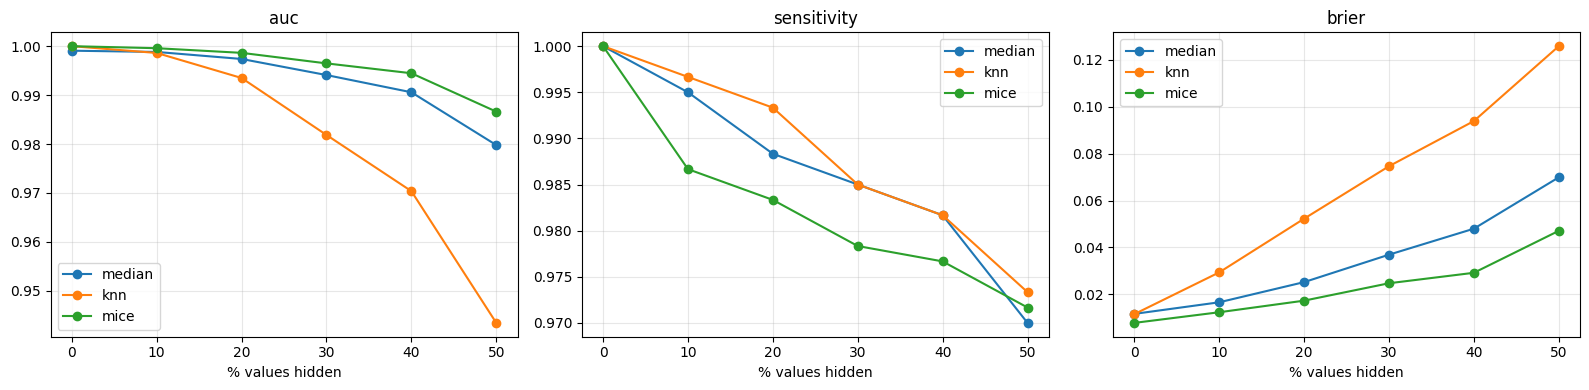

auc               sensitivity              
imputer      knn median   mice         knn median   mice
hidden_test                                             
al           1.0  0.999  1.000         1.0  0.983  1.000
hemo         1.0  0.999  0.997         1.0  1.000  0.983
sc           1.0  0.998  1.000         1.0  0.983  1.000

Best imputer: mice


In [13]:
# Step 6: Hide 10-50% of values (and whole key tests) and see how each imputer holds up
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import train_test_split

# Inner split of the TRAIN set only (the real test set is not touched)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.3,
                                            stratify=y_train, random_state=1)
imputers = ['median', 'knn', 'mice']
fitted = {imp: build_pipeline(make_model('RandForest'), imp, bin_idx, cont_idx).fit(X_tr, y_tr)
          for imp in imputers}

def hide_values(X, frac, seed):
    mask = np.random.default_rng(seed).random(X.shape) < frac
    return X.mask(mask)

# Part A: random missingness, 10 seeds each
res = []
for frac in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    for seed in range(10):
        Xm = hide_values(X_val, frac, seed)
        for imp in imputers:
            p = fitted[imp].predict_proba(Xm)[:, 1]
            res.append({'imputer': imp, 'missing': frac,
                        'auc': roc_auc_score(y_val, p),
                        'sensitivity': recall_score(y_val, (p >= 0.5).astype(int)),
                        'brier': brier_score_loss(y_val, p)})
res = pd.DataFrame(res)
summary = res.groupby(['imputer', 'missing']).mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['auc', 'sensitivity', 'brier']):
    for imp in imputers:
        d = summary[summary.imputer == imp]
        ax.plot(d.missing * 100, d[metric], marker='o', label=imp)
    ax.set_xlabel('% values hidden'); ax.set_title(metric); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Part B: hide one whole key test at a time
key_rows = []
for key in ['sc', 'hemo', 'al']:
    Xm = X_val.copy(); Xm[key] = np.nan
    for imp in imputers:
        p = fitted[imp].predict_proba(Xm)[:, 1]
        key_rows.append({'hidden_test': key, 'imputer': imp, 'auc': roc_auc_score(y_val, p),
                         'sensitivity': recall_score(y_val, (p >= 0.5).astype(int))})
display(pd.DataFrame(key_rows).pivot(index='hidden_test', columns='imputer',
                                     values=['auc', 'sensitivity']).round(3))

# Pick the imputer with the best average AUC across all missing levels
best_imp = summary.groupby('imputer')['auc'].mean().idxmax()
print("Best imputer:", best_imp)

In [14]:
# Step 7: Compare imbalance handling (none / class weights / SMOTENC) using the best imputer
rows = {}
for m in ['LogReg', 'RandForest', 'GradBoost']:
    for s in ['none', 'class_weight', 'smote']:
        if m == 'GradBoost' and s == 'class_weight':
            continue                                    # GradBoost has no class_weight option
        model = make_model(m, 'balanced' if s == 'class_weight' else None)
        pipe = build_pipeline(model, best_imp, bin_idx, cont_idx,
                              sampler='smote' if s == 'smote' else None)
        rows[(m, s)] = run_cv(pipe)

smote_df = pd.DataFrame(rows).T
display(smote_df[show_cols].round(3))

# Best combination = highest sensitivity, ties broken by ROC-AUC
best_model_name, best_strategy = smote_df.sort_values(['sensitivity', 'roc_auc'],
                                                      ascending=False).index[0]
print("Chosen:", best_model_name, "+", best_strategy)

roc_auc  pr_auc  sensitivity  sensitivity_sd  \
LogReg     none            1.000   1.000        0.990           0.015   
           class_weight    1.000   1.000        0.982           0.017   
           smote           1.000   1.000        0.985           0.015   
RandForest none            1.000   1.000        0.988           0.015   
           class_weight    1.000   1.000        0.992           0.012   
           smote           1.000   1.000        0.993           0.011   
GradBoost  none            0.987   0.990        0.978           0.020   
           smote           0.987   0.988        0.977           0.028   

                         specificity     f1  brier  
LogReg     none                1.000  0.995  0.008  
           class_weight        1.000  0.991  0.009  
           smote               1.000  0.992  0.008  
RandForest none                1.000  0.994  0.008  
           class_weight        1.000  0.996  0.007  
           smote               1.000  0.997  0.007  
GradBoost  none                0.983  0.984  0.019  
           smote               0.983  0.983  0.020

Chosen: RandForest + smote


In [15]:
# Step 8: RandomizedSearchCV on the chosen model + strategy (refit on ROC-AUC, sensitivity tracked)
from sklearn.model_selection import RandomizedSearchCV

grids = {
    'LogReg':     {'model__C': [0.01, 0.1, 1, 10, 100]},
    'RandForest': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [None, 3, 5, 8],
                   'model__min_samples_leaf': [1, 2, 4], 'model__max_features': ['sqrt', 'log2']},
    'GradBoost':  {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
                   'model__max_depth': [2, 3, 4], 'model__subsample': [0.7, 0.85, 1.0]},
}
grid = grids[best_model_name]
n_iter = int(min(20, np.prod([len(v) for v in grid.values()])))

base = build_pipeline(make_model(best_model_name, 'balanced' if best_strategy == 'class_weight' else None),
                      best_imp, bin_idx, cont_idx,
                      sampler='smote' if best_strategy == 'smote' else None)

search = RandomizedSearchCV(base, grid, n_iter=n_iter,
                            scoring={'roc_auc': 'roc_auc', 'sensitivity': 'recall'}, refit='roc_auc',
                            cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),
                            random_state=42, n_jobs=1)
search.fit(X_train, y_train)

b = search.best_index_
print("Best params:", search.best_params_)
print("CV ROC-AUC:", round(search.cv_results_['mean_test_roc_auc'][b], 4),
      "| CV sensitivity:", round(search.cv_results_['mean_test_sensitivity'][b], 4))

tuned_pipe = search.best_estimator_      # already fitted on the full training set

Best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
CV ROC-AUC: 0.9997 | CV sensitivity: 0.9925


Brier scores (lower is better): {'uncalibrated': np.float64(0.0095), 'sigmoid': np.float64(0.007), 'isotonic': np.float64(0.0044)}


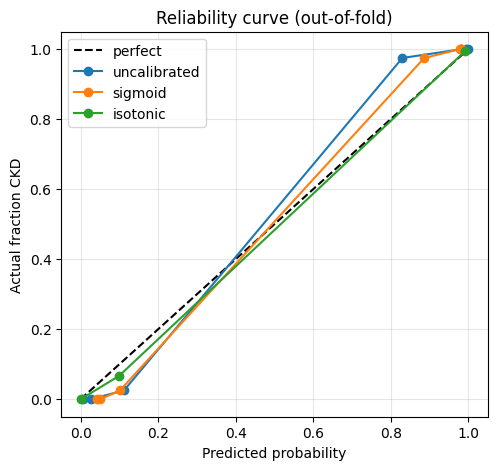

Chosen calibration: isotonic
Threshold: 0.675 | OOF sensitivity: 0.995 | OOF specificity: 1.000
Bands -> Low: < 0.68 | Moderate: 0.68 to 0.8 | High: >= 0.8


In [16]:
# Step 9: Calibrate (sigmoid vs isotonic), then pick a threshold for the target sensitivity
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve

TARGET_SENS = 0.97     # <- minimum sensitivity we want (change here if needed)
HIGH_CUT = 0.80        # probability above which the band is "high"

# Out-of-fold probabilities: uncalibrated vs sigmoid vs isotonic
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = {'uncalibrated': cross_val_predict(clone(tuned_pipe), X_train, y_train, cv=outer,
                                         method='predict_proba')[:, 1]}
for m in ['sigmoid', 'isotonic']:
    oof[m] = cross_val_predict(CalibratedClassifierCV(clone(tuned_pipe), method=m, cv=5),
                               X_train, y_train, cv=outer, method='predict_proba')[:, 1]

briers = {k: brier_score_loss(y_train, v) for k, v in oof.items()}
print("Brier scores (lower is better):", {k: round(v, 4) for k, v in briers.items()})

# Reliability curves
plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], 'k--', label='perfect')
for k, v in oof.items():
    frac_pos, mean_pred = calibration_curve(y_train, v, n_bins=8, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=k)
plt.xlabel('Predicted probability'); plt.ylabel('Actual fraction CKD')
plt.title('Reliability curve (out-of-fold)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

best_method = min(['sigmoid', 'isotonic'], key=lambda k: briers[k])
print("Chosen calibration:", best_method)

# Threshold: best specificity while keeping sensitivity >= TARGET_SENS (on out-of-fold probs)
p_oof = oof[best_method]
fpr, tpr, thr = roc_curve(y_train, p_oof)
ok = np.where(tpr >= TARGET_SENS)[0]
threshold = float(thr[ok[np.argmin(fpr[ok])]])

pred_oof = (p_oof >= threshold).astype(int)
print(f"Threshold: {threshold:.3f} | OOF sensitivity: {recall_score(y_train, pred_oof):.3f} "
      f"| OOF specificity: {recall_score(y_train, pred_oof, pos_label=0):.3f}")
print(f"Bands -> Low: < {threshold:.2f} | Moderate: {threshold:.2f} to {HIGH_CUT} | High: >= {HIGH_CUT}")

# Final calibrated model fitted on the full training set
final_model = CalibratedClassifierCV(clone(tuned_pipe), method=best_method, cv=5).fit(X_train, y_train)

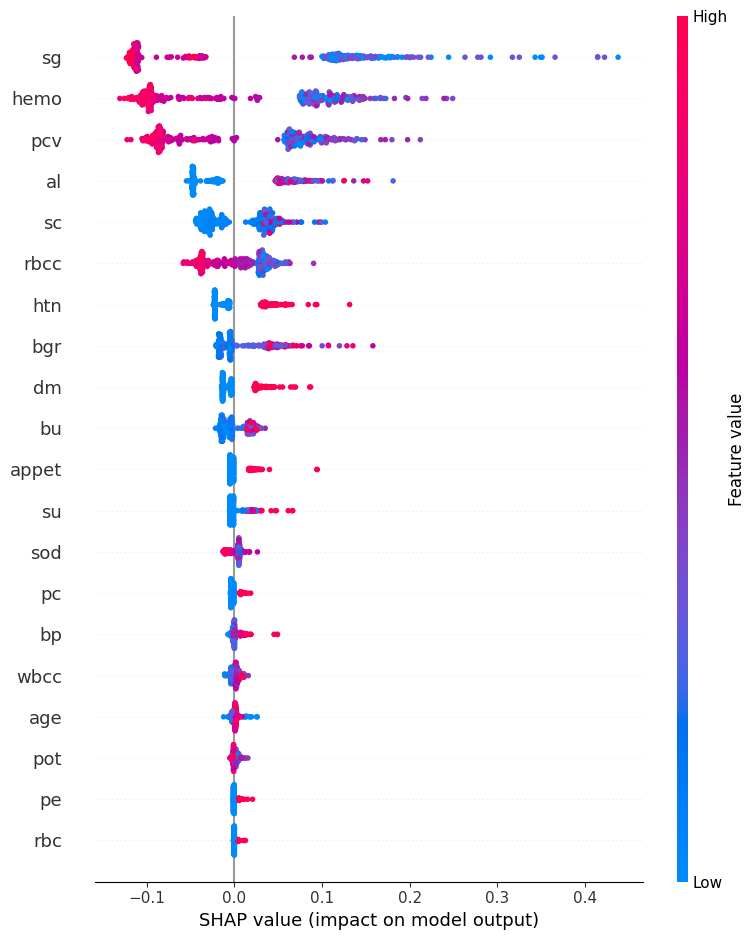

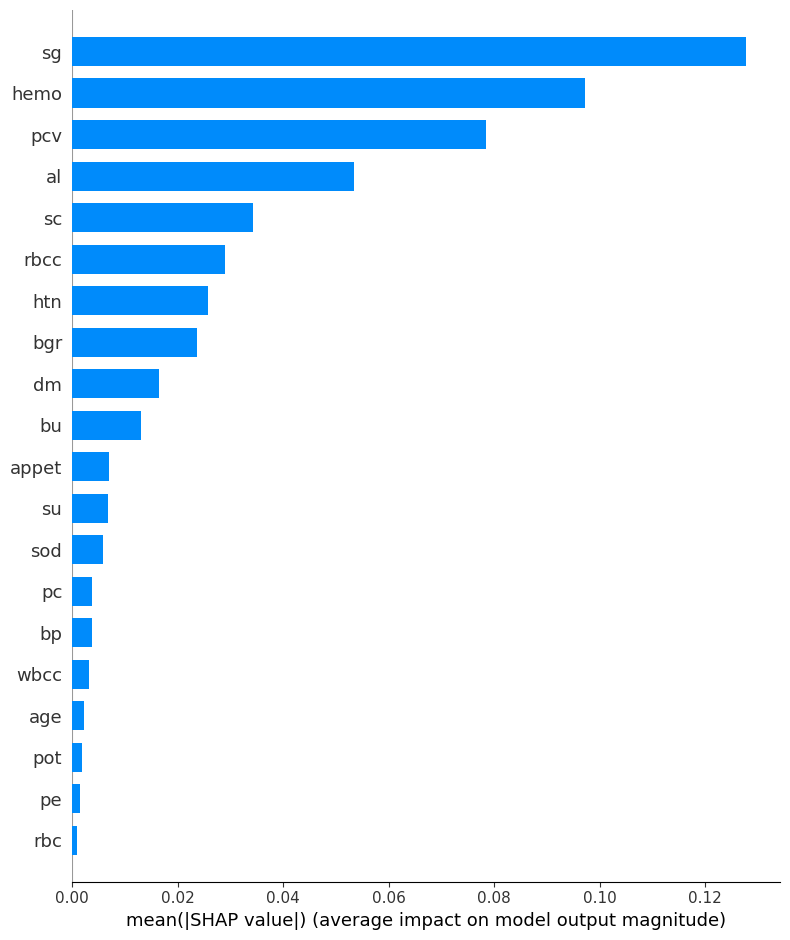

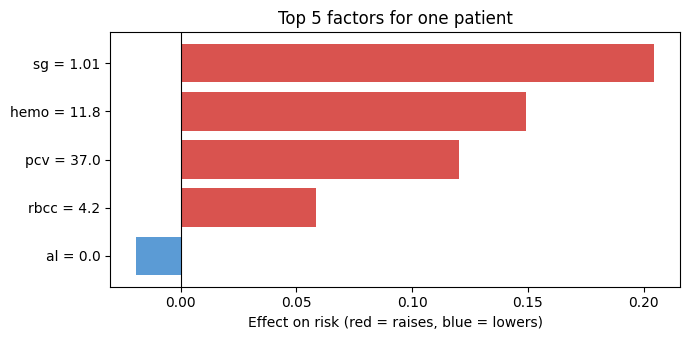

,SHAP top 8,Permutation top 8
0,sg,sg
1,hemo,hemo
2,pcv,pcv
3,al,rbcc
4,sc,al
5,rbcc,bu
6,htn,appet
7,bgr,sc


In [17]:
# Step 10: SHAP (global + per-patient) on the tuned pipeline, plus a permutation-importance cross-check
import shap
from sklearn.inspection import permutation_importance

model_step = tuned_pipe.named_steps['model']
Xt = preprocess(tuned_pipe, X_train)                      # imputed + scaled training data

if best_model_name == 'LogReg':
    explainer = shap.LinearExplainer(model_step, Xt)
    sv = explainer.shap_values(Xt)
else:
    explainer = shap.TreeExplainer(model_step)
    sv = explainer.shap_values(Xt, check_additivity=False)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[:, :, 1]

# Global plots
shap.summary_plot(sv, Xt, feature_names=feat_names, show=True)
shap.summary_plot(sv, Xt, feature_names=feat_names, plot_type='bar', show=True)

# Per-patient: top 5 factors for one CKD patient (values that were missing are marked "estimated")
i = int(np.where(y_train.values == 1)[0][0])
contrib = pd.Series(sv[i], index=feat_names)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:5]
labels = []
for f in top.index:
    v = X_train.iloc[i][f]
    labels.append(f"{f} = {'estimated' if pd.isna(v) else round(v, 2)}")
plt.figure(figsize=(7, 3.5))
plt.barh(labels[::-1], top.values[::-1], color=['#d9534f' if x > 0 else '#5b9bd5' for x in top.values[::-1]])
plt.axvline(0, color='k', lw=0.8); plt.xlabel('Effect on risk (red = raises, blue = lowers)')
plt.title('Top 5 factors for one patient'); plt.tight_layout(); plt.show()

# Cross-check with permutation importance
pi = permutation_importance(tuned_pipe, X_train, y_train, scoring='roc_auc', n_repeats=10, random_state=42)
perm_top = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)[:8]
shap_top = pd.Series(np.abs(sv).mean(0), index=feat_names).sort_values(ascending=False)[:8]
display(pd.DataFrame({'SHAP top 8': shap_top.index, 'Permutation top 8': perm_top.index}))

In [18]:
# Step 11: Use the test set ONCE, bootstrap 95% CIs, then save everything for the app
import os, joblib
from sklearn.metrics import average_precision_score, f1_score, confusion_matrix

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
yt_all = y_test.values

def metrics(yt, pp, pr):
    return [roc_auc_score(yt, pp), average_precision_score(yt, pp), recall_score(yt, pr),
            recall_score(yt, pr, pos_label=0), f1_score(yt, pr), brier_score_loss(yt, pp)]

names = ['ROC-AUC', 'PR-AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier']
point = metrics(yt_all, proba, pred)

rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt_all), len(yt_all))
    if len(np.unique(yt_all[idx])) < 2:
        continue
    boot.append(metrics(yt_all[idx], proba[idx], pred[idx]))
boot = np.array(boot)

final_table = pd.DataFrame({'Value': point,
                            'CI 2.5%': np.percentile(boot, 2.5, axis=0),
                            'CI 97.5%': np.percentile(boot, 97.5, axis=0)}, index=names).round(3)
display(final_table)
print("Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:\n", confusion_matrix(yt_all, pred))

# Save model + info the app needs
os.makedirs('models', exist_ok=True)
joblib.dump({
    'model': final_model,                 # calibrated model -> risk %
    'explain_pipe': tuned_pipe,           # uncalibrated pipeline -> SHAP
    'model_name': best_model_name,
    'features': cols,                     # raw input columns, in order
    'feature_order': feat_names,          # order the model sees (for SHAP labels)
    'threshold': threshold,
    'high_cut': HIGH_CUT,
    'train_min': X_train.min().to_dict(),
    'train_max': X_train.max().to_dict(),
    'train_median': X_train.median().to_dict(),
}, 'models/ckd_model.joblib')
print("Saved: models/ckd_model.joblib")

,Value,CI 2.5%,CI 97.5%
ROC-AUC,1.000,1.000,1.000
PR-AUC,1.000,1.000,1.000
Sensitivity,0.980,0.936,1.000
Specificity,1.000,1.000,1.000
F1,0.990,0.967,1.000
Brier,0.009,0.000,0.028


Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
 [[30  0]
 [ 1 49]]
Saved: models/ckd_model.joblib


In [19]:
# ILPD (Indian Liver Patient Dataset) - 583 Patients

In [20]:
pip install ucimlrepo

In [21]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
ilpd_indian_liver_patient_dataset = fetch_ucirepo(id=225)

# data (as pandas dataframes)
X = ilpd_indian_liver_patient_dataset.data.features
y = ilpd_indian_liver_patient_dataset.data.targets

# metadata
print(ilpd_indian_liver_patient_dataset.metadata)

# variable information
print(ilpd_indian_liver_patient_dataset.variables)


{'uci_id': 225, 'name': 'ILPD (Indian Liver Patient Dataset)', 'repository_url': 'https://archive.ics.uci.edu/dataset/225/ilpd+indian+liver+patient+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/225/data.csv', 'abstract': 'Death by liver cirrhosis continues to increase, given the increase in alcohol consumption rates, chronic hepatitis infections, and obesity-related liver disease. Notwithstanding the high mortality of this disease, liver diseases do not affect all sub-populations equally. The early detection of pathology is a determinant of patient outcomes, yet female patients appear to be marginalized when it comes to early diagnosis of liver pathology. \nThe dataset comprises 584 patient records collected from the NorthEast of Andhra Pradesh, India.\nThe prediction task is to determine whether a patient suffers from liver disease based on the information about several biochemical markers, including albumin and other enzymes required for metabolism.\n', 'area': 'He

In [22]:
import pandas as pd
from IPython.display import display, HTML

# Display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

# Fetch dataset
from ucimlrepo import fetch_ucirepo

ilpd_indian_liver_patient_dataset = fetch_ucirepo(id=225)

# Extract features and target
X = ilpd_indian_liver_patient_dataset.data.features
y = ilpd_indian_liver_patient_dataset.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Display the complete dataset in a scrollable HTML table
display(HTML(df.to_html(index=False)))

# Dataset information
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

Age,Gender,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/G Ratio,Selector
65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
26,Female,0.9,0.2,154,16,12,7.0,3.5,1.00,1
29,Female,0.9,0.3,202,14,11,6.7,3.6,1.10,1
17,Male,0.9,0.3,202,22,19,7.4,4.1,1.20,2
55,Male,0.7,0.2,290,53,58,6.8,3.4,1.00,1


Total rows: 583
Total columns: 11

Column names:
['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio', 'Selector']


In [23]:
# Step 1: Load the ILPD liver dataset from UCI (id 225)
from ucimlrepo import fetch_ucirepo

ilpd = fetch_ucirepo(id=225)
X = ilpd.data.features
y = ilpd.data.targets

print("Features:", X.shape, "| Target:", y.shape)
print("Columns:", list(X.columns))
print(y.iloc[:, 0].value_counts())

Features: (583, 10) | Target: (583, 1)
Columns: ['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio']
Selector
1    416
2    167
Name: count, dtype: int64


In [24]:
# Step 2: Clean -> `data` (numeric, Gender 1=Male) and `y_clean` (1 = liver patient, 0 = not)
import numpy as np
import pandas as pd

data = X.copy()
assert data.shape[1] == 10, "Unexpected column count"
data.columns = ['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'AG_ratio']

data['Gender'] = data['Gender'].astype(str).str.strip().str.lower().map({'male': 1, 'female': 0})
data = data.apply(pd.to_numeric, errors='coerce')

# Target: Selector 1 = liver patient, 2 = not a liver patient
y_clean = (y.iloc[:, 0].astype(int) == 1).astype(int)
y_clean.name = 'liver_disease'

# Remove duplicate rows (avoids the same patient landing in both train and test)
dup = data.duplicated()
print("Duplicate rows removed:", dup.sum())
data, y_clean = data[~dup], y_clean[~dup]

print("\nClass balance:\n", y_clean.value_counts())
print("\nNegative values:", int((data < 0).sum().sum()))

missing = pd.DataFrame({'missing_count': data.isna().sum(),
                        'missing_percent': (data.isna().mean() * 100).round(1)}
                       ).sort_values('missing_percent', ascending=False)
print("\nMissing-value report:")
display(missing)
display(data.describe().T.round(2))

Duplicate rows removed: 13

Class balance:
 liver_disease
1    406
0    164
Name: count, dtype: int64

Negative values: 0

Missing-value report:


,missing_count,missing_percent
AG_ratio,4,0.7
Age,0,0.0
Gender,0,0.0
TB,0,0.0
Alkphos,0,0.0
DB,0,0.0
Sgpt,0,0.0
Sgot,0,0.0
TP,0,0.0
ALB,0,0.0


,count,mean,std,min,25%,50%,75%,max
Age,570.0,44.85,16.24,4.0,33.0,45.00,58.00,90.0
Gender,570.0,0.75,0.43,0.0,1.0,1.00,1.00,1.0
TB,570.0,3.32,6.27,0.4,0.8,1.00,2.60,75.0
DB,570.0,1.50,2.83,0.1,0.2,0.30,1.30,19.7
Alkphos,570.0,291.75,245.29,63.0,176.0,208.00,298.00,2110.0
Sgpt,570.0,79.73,181.47,10.0,23.0,35.00,60.00,2000.0
Sgot,570.0,109.38,290.88,10.0,25.0,41.00,86.75,4929.0
TP,570.0,6.50,1.09,2.7,5.8,6.60,7.20,9.6
ALB,570.0,3.15,0.80,0.9,2.6,3.10,3.80,5.5
AG_ratio,566.0,0.95,0.32,0.3,0.7,0.95,1.10,2.8


In [25]:
%%writefile liver_utils.py
# Helper file: liver pipeline = log(enzymes) -> impute -> round 0/1 -> scale -> [SMOTE] -> model
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from pipeline_utils import get_imputer, RoundBinary


class LogCols(BaseEstimator, TransformerMixin):
    """log1p on skewed enzyme columns (NaN stays NaN)."""
    def __init__(self, log_idx=None):
        self.log_idx = log_idx

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.array(X, dtype=float).copy()
        if self.log_idx:
            X[:, self.log_idx] = np.log1p(np.clip(X[:, self.log_idx], 0, None))
        return X


def build_liver_pipeline(model, imputer_name, bin_idx, cont_idx, log_idx,
                         sampler=None, random_state=42):
    steps = [
        ('log', LogCols(log_idx=list(log_idx))),
        ('imputer', get_imputer(imputer_name)),
        ('round', RoundBinary(bin_idx=list(bin_idx))),
        ('scale', ColumnTransformer([('num', StandardScaler(), list(cont_idx))],
                                    remainder='passthrough')),
    ]
    if sampler == 'smote':
        n_c = len(cont_idx)
        steps.append(('smote', SMOTENC(categorical_features=list(range(n_c, n_c + len(bin_idx))),
                                       random_state=random_state)))
    steps.append(('model', model))
    return Pipeline(steps)

Writing liver_utils.py


In [26]:
# Step 3: 80/20 stratified split. The test set stays untouched until Cell 13.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data, y_clean, test_size=0.2, stratify=y_clean, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train liver %:", round(y_train.mean() * 100, 1), "| Test liver %:", round(y_test.mean() * 100, 1))
print("Females in test set:", int((X_test['Gender'] == 0).sum()))

Train: (456, 10) | Test: (114, 10)
Train liver %: 71.3 | Test liver %: 71.1
Females in test set: 33


In [27]:
# Setup: column groups, model factory, CV scheme and scoring used by all later cells
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from pipeline_utils import feature_order, preprocess
from liver_utils import build_liver_pipeline

cols = list(X_train.columns)
bin_cols = ['Gender']
log_cols = ['TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot']
cont_cols = [c for c in cols if c not in bin_cols]
bin_idx = [cols.index(c) for c in bin_cols]
cont_idx = [cols.index(c) for c in cont_cols]
log_idx = [cols.index(c) for c in log_cols]
feat_names = feature_order(cols, cont_idx, bin_idx)

def bp(model, imp, sampler=None):
    return build_liver_pipeline(model, imp, bin_idx, cont_idx, log_idx, sampler=sampler)

def make_model(name, class_weight=None):
    if name == 'LogReg':
        return LogisticRegression(max_iter=2000, class_weight=class_weight)
    if name == 'RandForest':
        return RandomForestClassifier(n_estimators=200, class_weight=class_weight,
                                      random_state=42, n_jobs=-1)
    if name == 'GradBoost':
        return GradientBoostingClassifier(random_state=42)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'sensitivity': 'recall',
           'specificity': make_scorer(recall_score, pos_label=0),
           'f1': 'f1', 'brier': 'neg_brier_score'}

def run_cv(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    out = {}
    for k in scoring:
        v = r['test_' + k] * (-1 if k == 'brier' else 1)
        out[k] = v.mean()
        out[k + '_sd'] = v.std()
    return out

show_cols = ['roc_auc', 'pr_auc', 'sensitivity', 'sensitivity_sd', 'specificity', 'f1', 'brier']

In [28]:
# Step 4: Baseline models (median imputer) with repeated 5-fold CV on the training set
rows = {}
for m in ['LogReg', 'RandForest', 'GradBoost']:
    rows[m] = run_cv(bp(make_model(m), 'median'))

baseline_df = pd.DataFrame(rows).T
display(baseline_df[show_cols].round(3))

,roc_auc,pr_auc,sensitivity,sensitivity_sd,specificity,f1,brier
LogReg,0.722,0.879,0.904,0.041,0.229,0.816,0.180
RandForest,0.723,0.878,0.862,0.040,0.290,0.802,0.182
GradBoost,0.694,0.858,0.837,0.061,0.306,0.790,0.204


In [29]:
# Step 5: Compare median vs KNN vs MICE imputation (same models, same CV)
rows = {}
for imp in ['median', 'knn', 'mice']:
    for m in ['LogReg', 'RandForest']:
        rows[(imp, m)] = run_cv(bp(make_model(m), imp))

imp_df = pd.DataFrame(rows).T
display(imp_df[show_cols].round(3))

roc_auc  pr_auc  sensitivity  sensitivity_sd  specificity  \
median LogReg        0.722   0.879        0.904           0.041        0.229   
       RandForest    0.723   0.878        0.862           0.040        0.290   
knn    LogReg        0.722   0.879        0.905           0.040        0.229   
       RandForest    0.724   0.879        0.858           0.036        0.295   
mice   LogReg        0.723   0.879        0.908           0.038        0.231   
       RandForest    0.722   0.879        0.854           0.035        0.297   

                      f1  brier  
median LogReg      0.816  0.180  
       RandForest  0.802  0.182  
knn    LogReg      0.816  0.180  
       RandForest  0.801  0.182  
mice   LogReg      0.818  0.180  
       RandForest  0.799  0.182

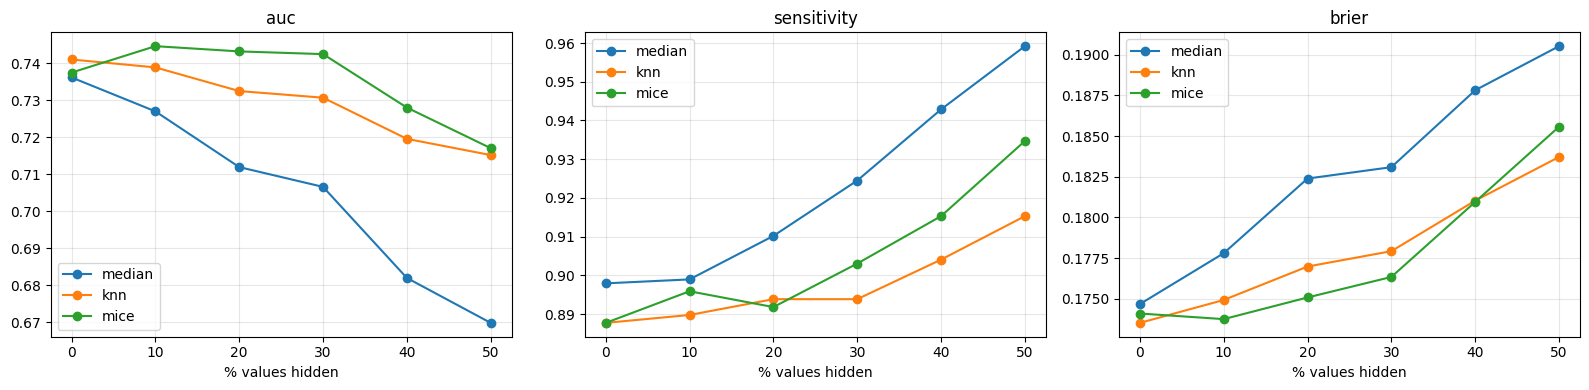

auc               sensitivity              
imputer        knn median   mice         knn median   mice
hidden_test                                               
ALB          0.743  0.755  0.733       0.918  0.959  0.878
Sgot         0.740  0.748  0.733       0.888  0.867  0.898
Sgpt         0.739  0.702  0.740       0.888  0.888  0.898

Best imputer: mice


In [30]:
# Step 6: Hide 10-50% of values (and whole key tests) and compare how each imputer holds up
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import train_test_split

# Inner split of the TRAIN set only (the real test set is not touched)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.3,
                                            stratify=y_train, random_state=1)
imputers = ['median', 'knn', 'mice']
fitted = {imp: bp(make_model('RandForest'), imp).fit(X_tr, y_tr) for imp in imputers}

def hide_values(X, frac, seed):
    mask = np.random.default_rng(seed).random(X.shape) < frac
    return X.mask(mask)

# Part A: random missingness, 10 seeds each
res = []
for frac in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    for seed in range(10):
        Xm = hide_values(X_val, frac, seed)
        for imp in imputers:
            p = fitted[imp].predict_proba(Xm)[:, 1]
            res.append({'imputer': imp, 'missing': frac,
                        'auc': roc_auc_score(y_val, p),
                        'sensitivity': recall_score(y_val, (p >= 0.5).astype(int)),
                        'brier': brier_score_loss(y_val, p)})
res = pd.DataFrame(res)
summary = res.groupby(['imputer', 'missing']).mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['auc', 'sensitivity', 'brier']):
    for imp in imputers:
        d = summary[summary.imputer == imp]
        ax.plot(d.missing * 100, d[metric], marker='o', label=imp)
    ax.set_xlabel('% values hidden'); ax.set_title(metric); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Part B: hide one whole key test at a time
key_rows = []
for key in ['Sgpt', 'Sgot', 'ALB']:
    Xm = X_val.copy(); Xm[key] = np.nan
    for imp in imputers:
        p = fitted[imp].predict_proba(Xm)[:, 1]
        key_rows.append({'hidden_test': key, 'imputer': imp, 'auc': roc_auc_score(y_val, p),
                         'sensitivity': recall_score(y_val, (p >= 0.5).astype(int))})
display(pd.DataFrame(key_rows).pivot(index='hidden_test', columns='imputer',
                                     values=['auc', 'sensitivity']).round(3))

best_imp = summary.groupby('imputer')['auc'].mean().idxmax()
print("Best imputer:", best_imp)

In [31]:
# Step 7: Compare imbalance handling (none / class weights / SMOTENC) using the best imputer
rows = {}
for m in ['LogReg', 'RandForest', 'GradBoost']:
    for s in ['none', 'class_weight', 'smote']:
        if m == 'GradBoost' and s == 'class_weight':
            continue
        model = make_model(m, 'balanced' if s == 'class_weight' else None)
        rows[(m, s)] = run_cv(bp(model, best_imp, sampler='smote' if s == 'smote' else None))

smote_df = pd.DataFrame(rows).T
display(smote_df[show_cols].round(3))

# Choose by ROC-AUC among options with sensitivity >= 0.80 (falls back to best AUC)
cand = smote_df[smote_df['sensitivity'] >= 0.80]
pool = cand if len(cand) > 0 else smote_df
best_model_name, best_strategy = pool.sort_values('roc_auc', ascending=False).index[0]
print("Chosen:", best_model_name, "+", best_strategy)

roc_auc  pr_auc  sensitivity  sensitivity_sd  \
LogReg     none            0.723   0.879        0.908           0.038   
           class_weight    0.723   0.879        0.586           0.062   
           smote           0.712   0.873        0.593           0.075   
RandForest none            0.722   0.879        0.854           0.035   
           class_weight    0.726   0.880        0.871           0.042   
           smote           0.720   0.876        0.749           0.058   
GradBoost  none            0.689   0.857        0.834           0.045   
           smote           0.690   0.855        0.724           0.068   

                         specificity     f1  brier  
LogReg     none                0.231  0.818  0.180  
           class_weight        0.765  0.696  0.212  
           smote               0.687  0.688  0.213  
RandForest none                0.297  0.799  0.182  
           class_weight        0.282  0.806  0.181  
           smote               0.486  0.765  0.192  
GradBoost  none                0.293  0.787  0.207  
           smote               0.493  0.750  0.214

Chosen: RandForest + class_weight


In [32]:
# Step 8: RandomizedSearchCV on the chosen model + strategy (refit on ROC-AUC)
from sklearn.model_selection import RandomizedSearchCV

grids = {
    'LogReg':     {'model__C': [0.01, 0.1, 1, 10, 100]},
    'RandForest': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [None, 3, 5, 8],
                   'model__min_samples_leaf': [1, 2, 4, 8], 'model__max_features': ['sqrt', 'log2']},
    'GradBoost':  {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
                   'model__max_depth': [2, 3, 4], 'model__subsample': [0.7, 0.85, 1.0]},
}
grid = grids[best_model_name]
n_iter = int(min(20, np.prod([len(v) for v in grid.values()])))

base = bp(make_model(best_model_name, 'balanced' if best_strategy == 'class_weight' else None),
          best_imp, sampler='smote' if best_strategy == 'smote' else None)

search = RandomizedSearchCV(base, grid, n_iter=n_iter,
                            scoring={'roc_auc': 'roc_auc', 'sensitivity': 'recall'}, refit='roc_auc',
                            cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42),
                            random_state=42, n_jobs=1)
search.fit(X_train, y_train)

b = search.best_index_
print("Best params:", search.best_params_)
print("CV ROC-AUC:", round(search.cv_results_['mean_test_roc_auc'][b], 4),
      "| CV sensitivity:", round(search.cv_results_['mean_test_sensitivity'][b], 4))

tuned_pipe = search.best_estimator_

Best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 8, 'model__max_features': 'sqrt', 'model__max_depth': None}
CV ROC-AUC: 0.7295 | CV sensitivity: 0.6846


Brier scores (lower is better): {'uncalibrated': np.float64(0.1958), 'sigmoid': np.float64(0.1812), 'isotonic': np.float64(0.1833)}


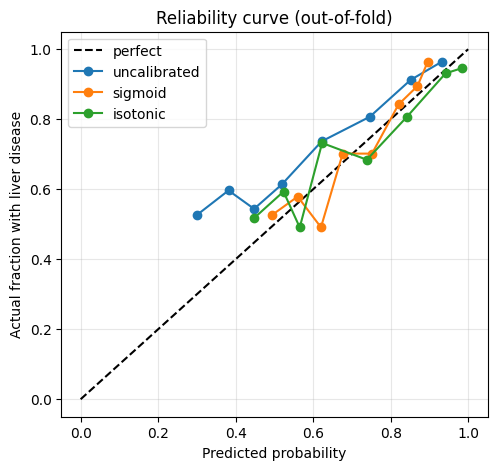

Chosen calibration: sigmoid
Threshold: 0.531 | OOF sensitivity: 0.908 | OOF specificity: 0.214
Bands -> Low: < 0.53 | Moderate: 0.53 to 0.80 | High: >= 0.80


In [33]:
# Step 9: Calibrate (sigmoid vs isotonic), then pick a threshold for the target sensitivity
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve

TARGET_SENS = 0.90     # <- minimum sensitivity wanted (liver is harder than kidney; 0.97 would flag nearly everyone)

outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = {'uncalibrated': cross_val_predict(clone(tuned_pipe), X_train, y_train, cv=outer,
                                         method='predict_proba')[:, 1]}
for m in ['sigmoid', 'isotonic']:
    oof[m] = cross_val_predict(CalibratedClassifierCV(clone(tuned_pipe), method=m, cv=5),
                               X_train, y_train, cv=outer, method='predict_proba')[:, 1]

briers = {k: brier_score_loss(y_train, v) for k, v in oof.items()}
print("Brier scores (lower is better):", {k: round(v, 4) for k, v in briers.items()})

plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], 'k--', label='perfect')
for k, v in oof.items():
    frac_pos, mean_pred = calibration_curve(y_train, v, n_bins=8, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=k)
plt.xlabel('Predicted probability'); plt.ylabel('Actual fraction with liver disease')
plt.title('Reliability curve (out-of-fold)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

best_method = min(['sigmoid', 'isotonic'], key=lambda k: briers[k])
print("Chosen calibration:", best_method)

# Threshold: best specificity while keeping sensitivity >= TARGET_SENS (out-of-fold)
p_oof = oof[best_method]
fpr, tpr, thr = roc_curve(y_train, p_oof)
ok = np.where(tpr >= TARGET_SENS)[0]
threshold = float(thr[ok[np.argmin(fpr[ok])]])
HIGH_CUT = float(min(0.95, max(0.80, threshold + 0.15)))

pred_oof = (p_oof >= threshold).astype(int)
print(f"Threshold: {threshold:.3f} | OOF sensitivity: {recall_score(y_train, pred_oof):.3f} "
      f"| OOF specificity: {recall_score(y_train, pred_oof, pos_label=0):.3f}")
print(f"Bands -> Low: < {threshold:.2f} | Moderate: {threshold:.2f} to {HIGH_CUT:.2f} | High: >= {HIGH_CUT:.2f}")

final_model = CalibratedClassifierCV(clone(tuned_pipe), method=best_method, cv=5).fit(X_train, y_train)

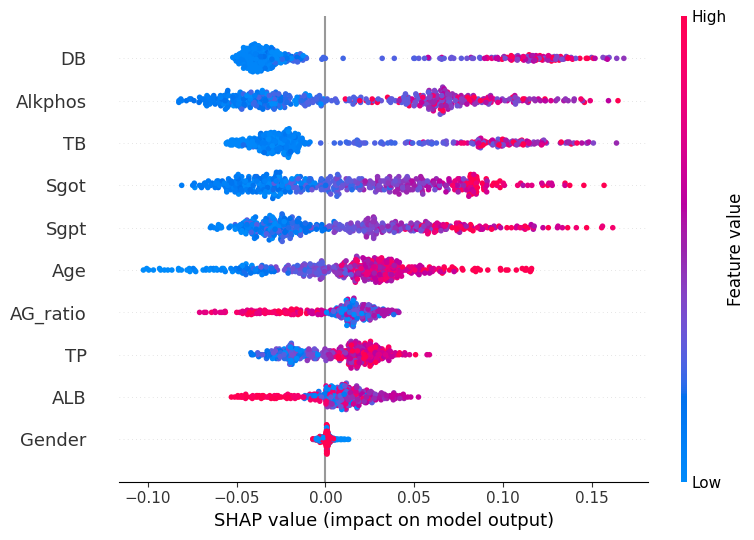

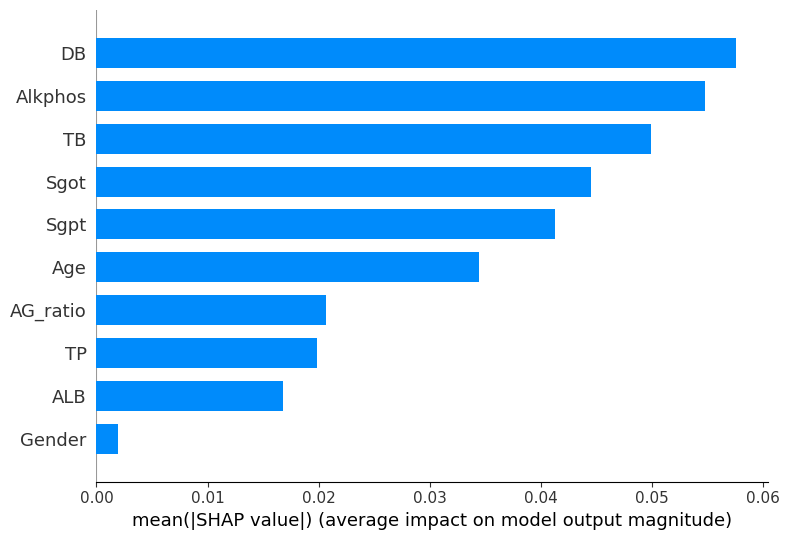

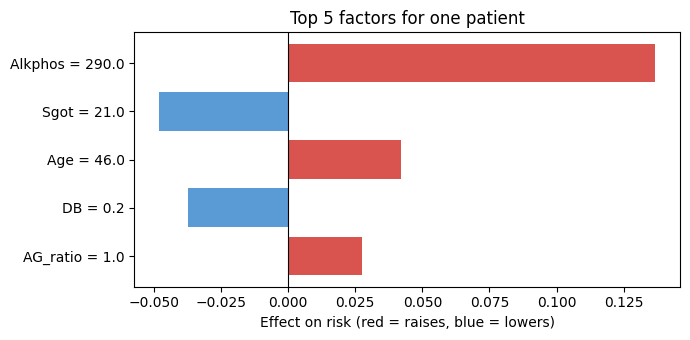

,SHAP top 8,Permutation top 8
0,DB,Alkphos
1,Alkphos,Sgot
2,TB,TB
3,Sgot,Sgpt
4,Sgpt,Age
5,Age,DB
6,AG_ratio,TP
7,TP,AG_ratio


In [34]:
# Step 10: SHAP (global + per-patient) on the tuned pipeline, plus a permutation-importance cross-check
import shap
from sklearn.inspection import permutation_importance

model_step = tuned_pipe.named_steps['model']
Xt = preprocess(tuned_pipe, X_train)          # log + imputed + scaled training data

if best_model_name == 'LogReg':
    explainer = shap.LinearExplainer(model_step, Xt)
    sv = explainer.shap_values(Xt)
else:
    explainer = shap.TreeExplainer(model_step)
    sv = explainer.shap_values(Xt, check_additivity=False)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, Xt, feature_names=feat_names, show=True)
shap.summary_plot(sv, Xt, feature_names=feat_names, plot_type='bar', show=True)

# Per-patient: top 5 factors for one liver patient (missing values are marked "estimated")
i = int(np.where(y_train.values == 1)[0][0])
contrib = pd.Series(sv[i], index=feat_names)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:5]
labels = []
for f in top.index:
    v = X_train.iloc[i][f]
    labels.append(f"{f} = {'estimated' if pd.isna(v) else round(v, 2)}")
plt.figure(figsize=(7, 3.5))
plt.barh(labels[::-1], top.values[::-1], color=['#d9534f' if x > 0 else '#5b9bd5' for x in top.values[::-1]])
plt.axvline(0, color='k', lw=0.8); plt.xlabel('Effect on risk (red = raises, blue = lowers)')
plt.title('Top 5 factors for one patient'); plt.tight_layout(); plt.show()

# Cross-check with permutation importance
pi = permutation_importance(tuned_pipe, X_train, y_train, scoring='roc_auc', n_repeats=10, random_state=42)
perm_top = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)[:8]
shap_top = pd.Series(np.abs(sv).mean(0), index=feat_names).sort_values(ascending=False)[:8]
display(pd.DataFrame({'SHAP top 8': shap_top.index, 'Permutation top 8': perm_top.index}))

In [35]:
# Step 11: Use the test set ONCE, bootstrap 95% CIs, results by sex, then save for the app
import os, joblib
from sklearn.metrics import average_precision_score, f1_score, confusion_matrix

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
yt_all = y_test.values

def metrics(yt, pp, pr):
    return [roc_auc_score(yt, pp), average_precision_score(yt, pp), recall_score(yt, pr),
            recall_score(yt, pr, pos_label=0), f1_score(yt, pr), brier_score_loss(yt, pp)]

names = ['ROC-AUC', 'PR-AUC', 'Sensitivity', 'Specificity', 'F1', 'Brier']
point = metrics(yt_all, proba, pred)

rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt_all), len(yt_all))
    if len(np.unique(yt_all[idx])) < 2:
        continue
    boot.append(metrics(yt_all[idx], proba[idx], pred[idx]))
boot = np.array(boot)

final_table = pd.DataFrame({'Value': point,
                            'CI 2.5%': np.percentile(boot, 2.5, axis=0),
                            'CI 97.5%': np.percentile(boot, 97.5, axis=0)}, index=names).round(3)
display(final_table)
print("Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:\n", confusion_matrix(yt_all, pred))

# Results by sex (small female group -> wide uncertainty)
sex_rows = {}
for label, g in [('Male', 1), ('Female', 0)]:
    m = (X_test['Gender'].values == g)
    if len(np.unique(yt_all[m])) == 2:
        sex_rows[label] = dict(zip(['n'] + names, [int(m.sum())] + metrics(yt_all[m], proba[m], pred[m])))
display(pd.DataFrame(sex_rows).T.round(3))

# Save model + info the app needs
os.makedirs('models', exist_ok=True)
joblib.dump({
    'model': final_model,                 # calibrated model -> risk %
    'explain_pipe': tuned_pipe,           # uncalibrated pipeline -> SHAP
    'model_name': best_model_name,
    'features': cols,                     # raw input columns, in order
    'feature_order': feat_names,          # order the model sees (for SHAP labels)
    'log_cols': log_cols,
    'threshold': threshold,
    'high_cut': HIGH_CUT,
    'train_min': X_train.min().to_dict(),
    'train_max': X_train.max().to_dict(),
    'train_median': X_train.median().to_dict(),
}, 'models/liver_model.joblib')
print("Saved: models/liver_model.joblib")

,Value,CI 2.5%,CI 97.5%
ROC-AUC,0.792,0.699,0.869
PR-AUC,0.915,0.863,0.954
Sensitivity,0.951,0.899,1.000
Specificity,0.182,0.059,0.324
F1,0.832,0.773,0.887
Brier,0.167,0.135,0.201


Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
 [[ 6 27]
 [ 4 77]]


,n,ROC-AUC,PR-AUC,Sensitivity,Specificity,F1,Brier
Male,81.0,0.814,0.918,0.964,0.16,0.824,0.169
Female,33.0,0.745,0.917,0.920,0.25,0.852,0.161


Saved: models/liver_model.joblib


In [36]:
# Helper: recompute test-set metrics from a saved model and write models/<name>_metrics.json
import json, joblib
import numpy as np, pandas as pd, sklearn
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix
import pipeline_utils, liver_utils   # must be imported so joblib can load the custom classes

def export_metrics(name, X_test, y_test):
    b = joblib.load(f'models/{name}_model.joblib')
    thr = b['threshold']
    proba = b['model'].predict_proba(X_test[b['features']])[:, 1]
    pred = (proba >= thr).astype(int)
    yt = y_test.values

    # bootstrap 95% CI for sensitivity (same seed/method as the final evaluation cell)
    rng = np.random.default_rng(42); sens_boot = []
    for _ in range(1000):
        idx = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[idx])) < 2:
            continue
        sens_boot.append(recall_score(yt[idx], pred[idx]))

    m = {
        'accuracy': float(accuracy_score(yt, pred)),
        'sensitivity': float(recall_score(yt, pred)),
        'specificity': float(recall_score(yt, pred, pos_label=0)),
        'roc_auc': float(roc_auc_score(yt, proba)),
        'sensitivity_ci': [float(np.percentile(sens_boot, 2.5)), float(np.percentile(sens_boot, 97.5))],
        'n_test': int(len(yt)),
        'threshold': float(thr),
        'high_cut': float(b['high_cut']),
        'model_name': b['model_name'],
        'sklearn_version': sklearn.__version__,
    }
    json.dump(m, open(f'models/{name}_metrics.json', 'w'), indent=2)
    print(json.dumps(m, indent=2))
    print("Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:\n", confusion_matrix(yt, pred))

In [37]:
# Kidney: reload data, rebuild the same test split, and export models/ckd_metrics.json
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

_ck = fetch_ucirepo(id=336)
_X, _y = _ck.data.features, _ck.data.targets

_bin = {'normal': 0, 'abnormal': 1, 'notpresent': 0, 'present': 1, 'no': 0, 'yes': 1, 'good': 0, 'poor': 1}
_d = _X.copy()
for c in _d.columns:
    if not pd.api.types.is_numeric_dtype(_d[c]):
        s = _d[c].astype(str).str.strip().str.lower()
        s = s.replace({'?': np.nan, '': np.nan, 'nan': np.nan, 'none': np.nan})
        _d[c] = s.replace(_bin)
_d = _d.apply(pd.to_numeric, errors='coerce')
_t = _y.iloc[:, 0].astype(str).str.strip().str.lower().map({'ckd': 1, 'notckd': 0}).astype(int)

_, Xte_k, _, yte_k = train_test_split(_d, _t, test_size=0.2, stratify=_t, random_state=42)
export_metrics('ckd', Xte_k, yte_k)

{
  "accuracy": 0.9875,
  "sensitivity": 0.98,
  "specificity": 1.0,
  "roc_auc": 1.0,
  "sensitivity_ci": [
    0.936153054221002,
    1.0
  ],
  "n_test": 80,
  "threshold": 0.6751906474071067,
  "high_cut": 0.8,
  "model_name": "RandForest",
  "sklearn_version": "1.6.1"
}
Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
 [[30  0]
 [ 1 49]]


In [38]:
# Liver: reload data, rebuild the same test split, and export models/liver_metrics.json
_il = fetch_ucirepo(id=225)
_X, _y = _il.data.features, _il.data.targets

_d = _X.copy()
_d.columns = ['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'AG_ratio']
_d['Gender'] = _d['Gender'].astype(str).str.strip().str.lower().map({'male': 1, 'female': 0})
_d = _d.apply(pd.to_numeric, errors='coerce')
_t = (_y.iloc[:, 0].astype(int) == 1).astype(int)
_dup = _d.duplicated()
_d, _t = _d[~_dup], _t[~_dup]

_, Xte_l, _, yte_l = train_test_split(_d, _t, test_size=0.2, stratify=_t, random_state=42)
export_metrics('liver', Xte_l, yte_l)

{
  "accuracy": 0.7280701754385965,
  "sensitivity": 0.9506172839506173,
  "specificity": 0.18181818181818182,
  "roc_auc": 0.7919940142162365,
  "sensitivity_ci": [
    0.8988728488124021,
    1.0
  ],
  "n_test": 114,
  "threshold": 0.5312947999722375,
  "high_cut": 0.8,
  "model_name": "RandForest",
  "sklearn_version": "1.6.1"
}
Confusion matrix [rows = actual 0/1, cols = predicted 0/1]:
 [[ 6 27]
 [ 4 77]]


In [39]:
# Copy everything the web app needs to Google Drive and also download it as one zip
import os, shutil, zipfile
from google.colab import drive, files

drive.mount('/content/drive')
dest = '/content/drive/MyDrive/ckd_liver_project'
os.makedirs(dest + '/models', exist_ok=True)

needed = ['pipeline_utils.py', 'liver_utils.py',
          'models/ckd_model.joblib', 'models/liver_model.joblib',
          'models/ckd_metrics.json', 'models/liver_metrics.json']
for f in needed:
    shutil.copy(f, os.path.join(dest, f))

with zipfile.ZipFile('web_app_files.zip', 'w') as z:
    for f in needed:
        z.write(f)
print("Copied to Drive folder:", dest)
print("scikit-learn version to install on your laptop: pip install scikit-learn==" + sklearn.__version__)
files.download('web_app_files.zip')

Mounted at /content/drive
Copied to Drive folder: /content/drive/MyDrive/ckd_liver_project
scikit-learn version to install on your laptop: pip install scikit-learn==1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import os

for f in ["models/ckd_model.joblib", "models/liver_model.joblib"]:
    print("FOUND:" if os.path.exists(f) else "MISSING:", f)

FOUND: models/ckd_model.joblib
FOUND: models/liver_model.joblib


In [41]:
from google.colab import files

files.download("models/ckd_model.joblib")
files.download("models/liver_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import os

path = "/content/models/ckd_model.joblib"

print("File exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")
else:
    print("Files inside /content:")
    for root, dirs, files in os.walk("/content"):
        for f in files:
            if "ckd" in f.lower():
                print(os.path.join(root, f))

File exists: True
File size: 7584644 bytes


In [46]:
from google.colab import files
files.download("/content/models/ckd_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>